In [2]:
!pip install scikit-fuzzy
!pip install git+https://github.com/twmeggs/anfis.git

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 15.7 MB/s eta 0:00:00
  Cloning https://github.com/twmeggs/anfis.git to /tmp/pip-req-build-tf6qk0rj
  Running command git clone --filter=blob:none --quiet https://github.com/twmeggs/anfis.git /tmp/pip-req-build-tf6qk0rj
  Resolved https://github.com/twmeggs/anfis.git to commit f48f935941086246a4d49c9bc56d2fc357846008
  Preparing metadata (setup.py) ... done
  Created wheel for anfis: filename=anfis-0.3.1-py3-none-any.whl size=8217 sha256=d5977d7801415f37ba1ee63290400bd994186c3ad4c354e3278860d7eb279fb8
  Stored in directory: /tmp/pip-ephem-wheel-cache-tkx97vau/wheels/07/38/05/05ab0b60f46ffd248e00919625c0bbc80cd31b64328f36e1f6
Successfully built anfis


In [14]:
# 1. تنصيب المكتبة
!pip install scikit-fuzzy
!pip install git+https://github.com/twmeggs/anfis.git

# 2. كود سحري لإصلاح خطأ المكتبة داخلياً (Fixing the internal imports)
import os
import sys

# تحديد مسار المكتبة في كولاب
lib_path = '/usr/local/lib/python3.12/dist-packages/anfis/'

# إصلاح ملف __init__.py لتصحيح المسارات
init_file = os.path.join(lib_path, 'membership/__init__.py')
with open(init_file, 'w') as f:
    f.write('from . import membershipfunction\nfrom . import mfDerivs')

# إضافة المسار لنظام بايثون
sys.path.append(lib_path)

# 3. الآن الاستدعاء الصحيح
try:
    from anfis import anfis

    from anfis.membership import membershipfunction
    print("✅ أخيراً! البيئة جاهزة والـ ANFIS شغال 100%")
except Exception as e:
    print(f"❌ لسه في مشكلة: {e}")

  Cloning https://github.com/twmeggs/anfis.git to /tmp/pip-req-build-jp2lcxnc
  Running command git clone --filter=blob:none --quiet https://github.com/twmeggs/anfis.git /tmp/pip-req-build-jp2lcxnc
  Resolved https://github.com/twmeggs/anfis.git to commit f48f935941086246a4d49c9bc56d2fc357846008
  Preparing metadata (setup.py) ... done
✅ أخيراً! البيئة جاهزة والـ ANFIS شغال 100%


In [3]:
import numpy as np
import skfuzzy as fuzz
import matplotlib.pyplot as plt
from skfuzzy import control as ctrl

In [4]:
Speed= ctrl.Antecedent(np.arange(0, 121, 0.1), 'Speed')
Road_condition= ctrl.Antecedent(np.arange(0, 11, 0.1), 'Road_condition')
Driver_alertness = ctrl.Antecedent(np.arange(0, 11, 0.1), 'Driver_alertness')
Risk_level = ctrl.Consequent(np.arange(0, 11, 0.1), 'Risk_level')

In [5]:
Speed['slow'] = fuzz.trimf(Speed.universe, [0, 25, 50])
Speed['medium'] = fuzz.trimf(Speed.universe, [30, 55, 80])
Speed['fast'] = fuzz.trimf(Speed.universe, [70, 100, 120])
Road_condition['poor'] = fuzz.trimf(Road_condition.universe, [0, 2, 6])
Road_condition['normal'] = fuzz.trimf(Road_condition.universe, [4, 5, 8 ])
Road_condition['good'] = fuzz.trimf(Road_condition.universe, [7, 8, 10])
Driver_alertness['low'] = fuzz.trimf(Driver_alertness.universe, [0, 3, 5.5])
Driver_alertness['medium'] = fuzz.trimf(Driver_alertness.universe, [4 , 6 ,8 ])
Driver_alertness['high'] = fuzz.trimf(Driver_alertness.universe, [6.5, 8, 10])
Risk_level['low_risk'] = fuzz.trimf(Risk_level.universe, [0, 2, 4 ])
Risk_level['medium_risk'] = fuzz.trimf(Risk_level.universe,[3.5, 5.5 ,7])
Risk_level['high_risk'] = fuzz.trimf(Risk_level.universe, [6.5, 8 , 10])

In [6]:
rule1  = ctrl.Rule(Speed['fast'] & Road_condition['poor'] & Driver_alertness['low'],    Risk_level['high_risk'])
rule2  = ctrl.Rule(Speed['fast'] & Road_condition['poor'] & Driver_alertness['medium'], Risk_level['high_risk'])
rule3  = ctrl.Rule(Speed['fast'] & Road_condition['poor'] & Driver_alertness['high'],   Risk_level['high_risk'])
rule4  = ctrl.Rule(Speed['fast'] & Road_condition['normal'] & Driver_alertness['low'],  Risk_level['high_risk'])
rule5  = ctrl.Rule(Speed['fast'] & Road_condition['normal'] & Driver_alertness['medium'], Risk_level['high_risk'])
rule6  = ctrl.Rule(Speed['fast'] & Road_condition['normal'] & Driver_alertness['high'], Risk_level['medium_risk'])
rule7  = ctrl.Rule(Speed['fast'] & Road_condition['good'] & Driver_alertness['low'],    Risk_level['high_risk'])
rule8  = ctrl.Rule(Speed['fast'] & Road_condition['good'] & Driver_alertness['medium'], Risk_level['medium_risk'])
rule9  = ctrl.Rule(Speed['fast'] & Road_condition['good'] & Driver_alertness['high'],   Risk_level['medium_risk'])
rule10 = ctrl.Rule(Speed['medium'] & Road_condition['poor'] & Driver_alertness['low'],    Risk_level['high_risk'])
rule11 = ctrl.Rule(Speed['medium'] & Road_condition['poor'] & Driver_alertness['medium'], Risk_level['medium_risk'])
rule12 = ctrl.Rule(Speed['medium'] & Road_condition['poor'] & Driver_alertness['high'],   Risk_level['medium_risk'])
rule13 = ctrl.Rule(Speed['medium'] & Road_condition['normal'] & Driver_alertness['low'],  Risk_level['medium_risk'])
rule14 = ctrl.Rule(Speed['medium'] & Road_condition['normal'] & Driver_alertness['medium'], Risk_level['medium_risk'])
rule15 = ctrl.Rule(Speed['medium'] & Road_condition['normal'] & Driver_alertness['high'], Risk_level['low_risk'])
rule16 = ctrl.Rule(Speed['medium'] & Road_condition['good'] & Driver_alertness['low'],    Risk_level['medium_risk'])
rule17 = ctrl.Rule(Speed['medium'] & Road_condition['good'] & Driver_alertness['medium'], Risk_level['low_risk'])
rule18 = ctrl.Rule(Speed['medium'] & Road_condition['good'] & Driver_alertness['high'],   Risk_level['low_risk'])
rule19 = ctrl.Rule(Speed['slow'] & Road_condition['poor'] & Driver_alertness['low'],    Risk_level['medium_risk'])
rule20 = ctrl.Rule(Speed['slow'] & Road_condition['poor'] & Driver_alertness['medium'], Risk_level['medium_risk'])
rule21 = ctrl.Rule(Speed['slow'] & Road_condition['poor'] & Driver_alertness['high'],   Risk_level['low_risk'])
rule22 = ctrl.Rule(Speed['slow'] & Road_condition['normal'] & Driver_alertness['low'],  Risk_level['medium_risk'])
rule23 = ctrl.Rule(Speed['slow'] & Road_condition['normal'] & Driver_alertness['medium'], Risk_level['low_risk'])
rule24 = ctrl.Rule(Speed['slow'] & Road_condition['normal'] & Driver_alertness['high'], Risk_level['low_risk'])
rule25 = ctrl.Rule(Speed['slow'] & Road_condition['good'] & Driver_alertness['low'],    Risk_level['low_risk'])
rule26 = ctrl.Rule(Speed['slow'] & Road_condition['good'] & Driver_alertness['medium'], Risk_level['low_risk'])
rule27 = ctrl.Rule(Speed['slow'] & Road_condition['good'] & Driver_alertness['high'],   Risk_level['low_risk'])

In [7]:
Risk_level_ctrl = ctrl.ControlSystem([rule1, rule2, rule3, rule4, rule5,rule6, rule7, rule8, rule9,rule10, rule11, rule12, rule13, rule14,rule15, rule16, rule17, rule18,rule19, rule20, rule21, rule22,rule23, rule24, rule25, rule26, rule27])
Risk_level_simulation = ctrl.ControlSystemSimulation(Risk_level_ctrl)

In [9]:
Risk_level_simulation.compute()

In [8]:
Risk_level_simulation.input['Speed'] = 80
Risk_level_simulation.input['Road_condition'] = 6
Risk_level_simulation.input['Driver_alertness'] = 3

In [10]:
print(f"Risk level is : {Risk_level_simulation.output['Risk_level']:.2f}")

Risk level is : 8.21


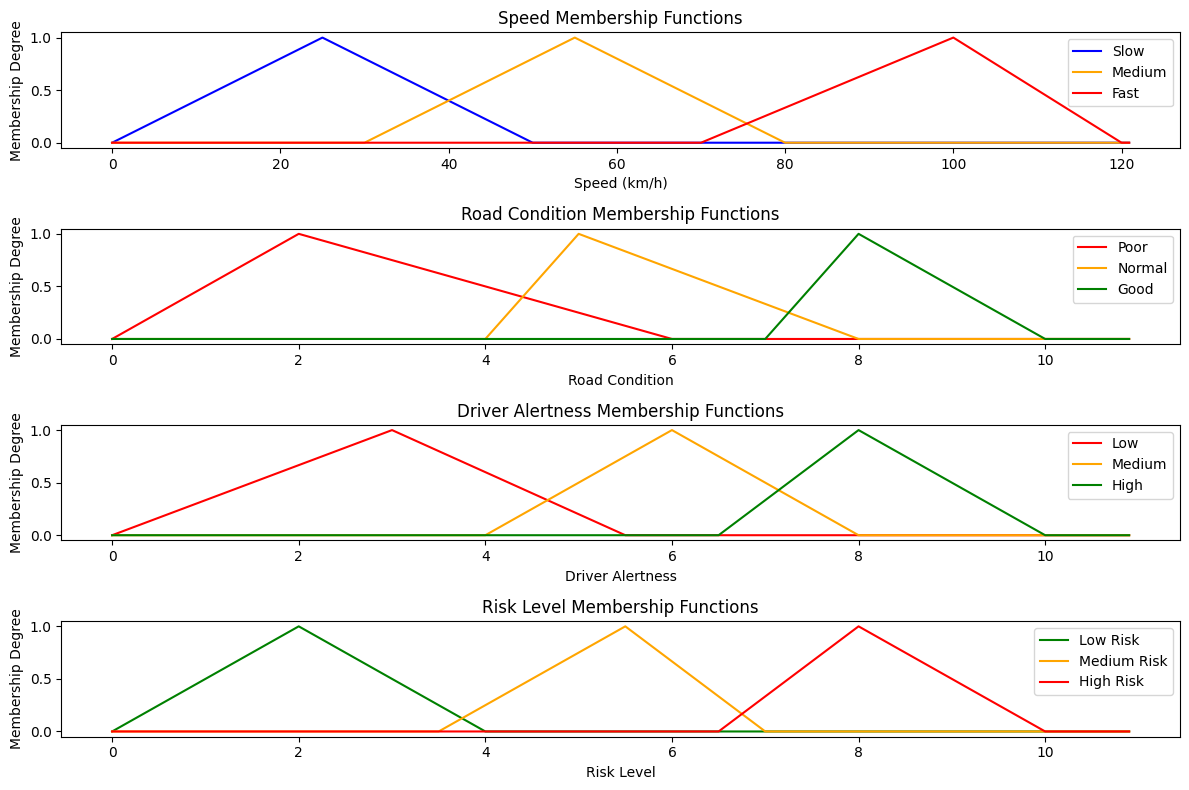

In [11]:
plt.figure(figsize=(12, 8))

# Speed
plt.subplot(4, 1, 1)
plt.plot(Speed.universe, Speed['slow'].mf, 'b', label='Slow')
plt.plot(Speed.universe, Speed['medium'].mf, 'orange', label='Medium')
plt.plot(Speed.universe, Speed['fast'].mf, 'r', label='Fast')
plt.title('Speed Membership Functions')
plt.xlabel('Speed (km/h)')
plt.ylabel('Membership Degree')
plt.legend()

# Road Condition
plt.subplot(4, 1, 2)
plt.plot(Road_condition.universe, Road_condition['poor'].mf, 'r', label='Poor')
plt.plot(Road_condition.universe, Road_condition['normal'].mf, 'orange', label='Normal')
plt.plot(Road_condition.universe, Road_condition['good'].mf, 'g', label='Good')
plt.title('Road Condition Membership Functions')
plt.xlabel('Road Condition')
plt.ylabel('Membership Degree')
plt.legend()

# Driver Alertness
plt.subplot(4, 1, 3)
plt.plot(Driver_alertness.universe, Driver_alertness['low'].mf, 'r', label='Low')
plt.plot(Driver_alertness.universe, Driver_alertness['medium'].mf, 'orange', label='Medium')
plt.plot(Driver_alertness.universe, Driver_alertness['high'].mf, 'g', label='High')
plt.title('Driver Alertness Membership Functions')
plt.xlabel('Driver Alertness')
plt.ylabel('Membership Degree')
plt.legend()

# Risk Level
plt.subplot(4, 1, 4)
plt.plot(Risk_level.universe, Risk_level['low_risk'].mf, 'g', label='Low Risk')
plt.plot(Risk_level.universe, Risk_level['medium_risk'].mf, 'orange', label='Medium Risk')
plt.plot(Risk_level.universe, Risk_level['high_risk'].mf, 'r', label='High Risk')
plt.title('Risk Level Membership Functions')
plt.xlabel('Risk Level')
plt.ylabel('Membership Degree')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from itertools import product

speeds = np.linspace(0, 120, 6)
roads = np.linspace(0, 10, 4)
alerts = np.linspace(0, 10, 4)

combinations = list(product(speeds, roads, alerts))
X = np.array(combinations)

Y_risk = []
print(f"⏳ يتم الآن عمل Evaluation لـ {len(X)} حالة...")

for i in range(len(X)):
    Risk_level_simulation.input['Speed'] = X[i, 0]
    Risk_level_simulation.input['Road_condition'] = X[i, 1]
    Risk_level_simulation.input['Driver_alertness'] = X[i, 2]
    try:
        Risk_level_simulation.compute()
        Y_risk.append(Risk_level_simulation.output['Risk_level'])
    except:
        Y_risk.append(5.0)

Y = np.array(Y_risk)
data_table = pd.DataFrame(X, columns=['Speed', 'Road', 'Alertness'])
data_table['Target_Risk'] = Y
display(data_table.head(10))

⏳ يتم الآن عمل Evaluation لـ 96 حالة...


,Speed,Road,Alertness,Target_Risk
0,0.0,0.000000,0.000000,5.0
1,0.0,0.000000,3.333333,5.0
2,0.0,0.000000,6.666667,5.0
3,0.0,0.000000,10.000000,5.0
4,0.0,3.333333,0.000000,5.0
5,0.0,3.333333,3.333333,5.0
6,0.0,3.333333,6.666667,5.0
7,0.0,3.333333,10.000000,5.0
8,0.0,6.666667,0.000000,5.0
9,0.0,6.666667,3.333333,5.0


In [ ]:
import numpy as np
if not hasattr(np, 'product'):
    np.product = np.prod

from anfis import anfis
from anfis.membership import membershipfunction

mf = [
    [['gaussmf', {'mean': 25., 'sigma': 15.}], ['gaussmf', {'mean': 55., 'sigma': 15.}], ['gaussmf', {'mean': 100., 'sigma': 15.}]],
    [['gaussmf', {'mean': 2., 'sigma': 2.}], ['gaussmf', {'mean': 5., 'sigma': 2.}], ['gaussmf', {'mean': 8., 'sigma': 2.}]],
    [['gaussmf', {'mean': 3., 'sigma': 2.}], ['gaussmf', {'mean': 6., 'sigma': 2.}], ['gaussmf', {'mean': 8., 'sigma': 2.}]]
]

mfc = membershipfunction.MemFuncs(mf)
anfis_model = anfis.ANFIS(X, Y, mfc)

print("⏳ بدأ تدريب الـ ANFIS...")
try:
    anfis_model.trainHybridJangOffLine(epochs=20)
    print("🎯 تم التدريب بنجاح.")
except Exception as e:
    print(f"❌ حدث خطأ: {e}")

⏳ بدأ تدريب الـ ANFIS...
current error: 5.438132989077047
current error: 5.433549479742808
current error: 5.428934564658332
current error: 5.424288764664095
current error: 5.419142641943639
current error: 5.413439528960936
current error: 5.407116033262605
current error: 5.400101276799358
current error: 5.392316094715509
current error: 5.383672220383671
current error: 5.374071501720809
current error: 5.3634052219867066
current error: 5.351553638274961
current error: 5.338385909806409
current error: 5.323760672999679
current error: 5.3075276317944855
current error: 5.289530688658677
current error: 5.269613325181584
current error: 5.247627150205907
🎯 تم التدريب بنجاح.


📊 قيمة الـ RMSE النهائية هي: 0.2343


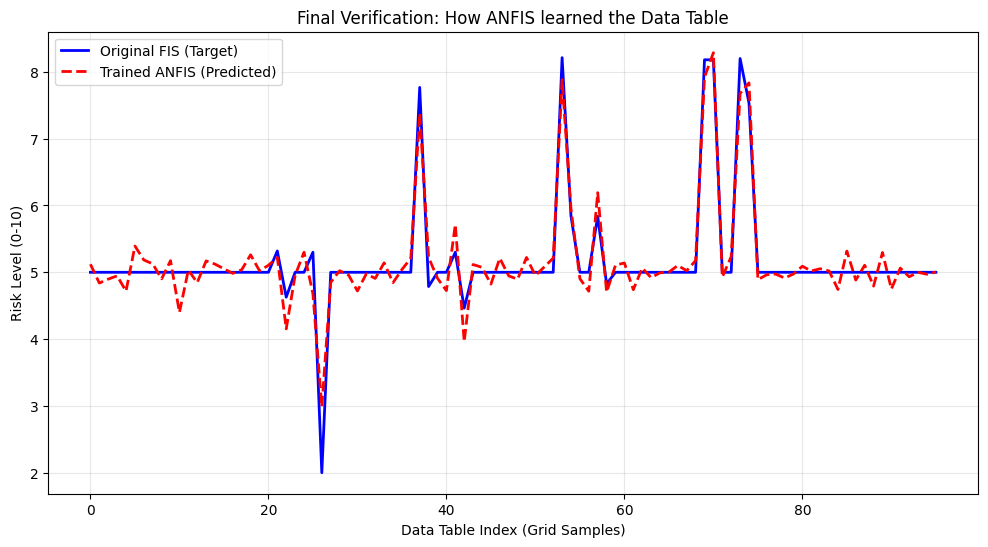

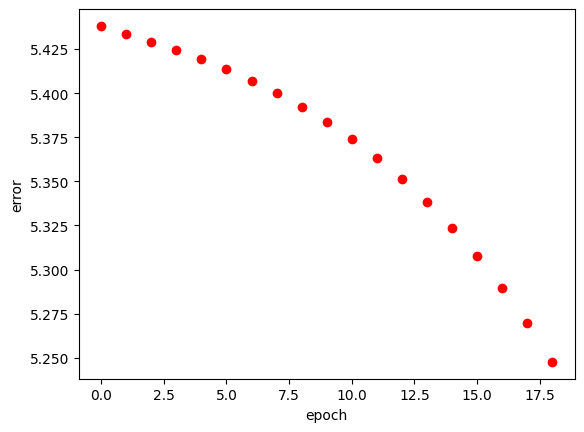

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

Y_pred = anfis_model.fittedValues

rmse = np.sqrt(mean_squared_error(Y, Y_pred))
print(f"📊 قيمة الـ RMSE النهائية هي: {rmse:.4f}")

plt.figure(figsize=(12, 6))
plt.plot(Y, 'b-', linewidth=2, label='Original FIS (Target)')
plt.plot(Y_pred, 'r--', linewidth=2, label='Trained ANFIS (Predicted)')
plt.title('Final Verification: How ANFIS learned the Data Table')
plt.xlabel('Data Table Index (Grid Samples)')
plt.ylabel('Risk Level (0-10)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

anfis_model.plotErrors()